In [25]:
import pandas as pd
import numpy as np
import sys  
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats

print ("All ok")
print (sys.executable)

All ok
c:\Users\roger.peloso\Desktop\major\.venv\Scripts\python.exe


# **1. Entendendo a tabela de jogos**

In [57]:
warnings.filterwarnings("ignore")

sns.set_style('whitegrid')
plt.rcParams['figure.figsize']=(12,6)

In [ ]:
path= "cs2_tier1_games.csv"

df_matches= pd.read_csv(path)
print ({df_matches.shape})
pd.set_option('display.max_columns',None)
df_matches.head(5)

{(22856, 2)}


,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,datetime,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,team1_player4_id,team1_player5_id,team2_player1_id,team2_player2_id,team2_player3_id,team2_player4_id,team2_player5_id,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5,team1_player1_kills,team1_player1_deaths,team1_player1_assists,team1_player1_adr,team1_player1_kast,team1_player1_kddiff,team1_player2_kills,team1_player2_deaths,team1_player2_assists,team1_player2_adr,team1_player2_kast,team1_player2_kddiff,team1_player3_kills,team1_player3_deaths,team1_player3_assists,team1_player3_adr,team1_player3_kast,team1_player3_kddiff,team1_player4_kills,team1_player4_deaths,team1_player4_assists,team1_player4_adr,team1_player4_kast,team1_player4_kddiff,team1_player5_kills,team1_player5_deaths,team1_player5_assists,team1_player5_adr,team1_player5_kast,team1_player5_kddiff,team2_player1_kills,team2_player1_deaths,team2_player1_assists,team2_player1_adr,team2_player1_kast,team2_player1_kddiff,team2_player2_kills,team2_player2_deaths,team2_player2_assists,team2_player2_adr,team2_player2_kast,team2_player2_kddiff,team2_player3_kills,team2_player3_deaths,team2_player3_assists,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
0,7312892,-156014.0,IEM Beijing 2026,307019,MOUZ,307020,BETBOOM TEAM,2.0,0.0,True,3.0,NaN,NaN,NaN,NaN,2026-11-07 12:45:00,1.0,2.0,6284.0,26888.0,3060.0,3121.0,2126.0,1092.0,3289.0,457.0,5420.0,2936.0,"PR (Oldřich Nový), CZ",xelex,"Spinx (Lotan Giladi), IL","xertioN (Dorian Berman), IL","torzsi (Ádám Torzsás), HU","zorte (Alexandr Zagodyrenko), RU","d1Ledez (Daniil Kustov), RU","Boombl4 (Kirill Mikhailov), RU","Magnojez (Kirill Rodnov), RU","s1ren (Pavel Ogloblin), RU",35.0,20.0,12.0,90.5,78.0,15.0,22.0,23.0,14.0,72.8,82.9,-1.0,23.0,23.0,12.0,61.7,90.5,0.0,40.0,20.0,10.0,111.3,73.2,20.0,30.0,18.0,13.0,63.9,73.2,12.0,17.0,27.0,7.0,45.3,61.3,-10.0,18.0,34.0,7.0,56.3,66.2,-16.0,22.0,33.0,9.0,65.1,53.7,-11.0,17.0,28.0,8.0,58.7,58.6,-11.0,30.0,28.0,4.0,80.3,61.2,2.0
1,7312892,156014.0,IEM Beijing 2026,307019,MOUZ,307020,BETBOOM TEAM,2.0,0.0,False,3.0,13.0,7.0,24.0,Ancient,2026-11-07 12:45:00,1.0,2.0,6284.0,26888.0,3060.0,3121.0,2126.0,1092.0,3289.0,457.0,5420.0,2936.0,"PR (Oldřich Nový), CZ",xelex,"Spinx (Lotan Giladi), IL","xertioN (Dorian Berman), IL","torzsi (Ádám Torzsás), HU","zorte (Alexandr Zagodyrenko), RU","d1Ledez (Daniil Kustov), RU","Boombl4 (Kirill Mikhailov), RU","Magnojez (Kirill Rodnov), RU","s1ren (Pavel Ogloblin), RU",17.0,11.0,7.0,90.9,75.0,6.0,7.0,13.0,9.0,62.5,80.0,-6.0,14.0,11.0,7.0,71.0,100.0,3.0,21.0,11.0,8.0,119.8,75.0,10.0,15.0,10.0,3.0,65.5,75.0,5.0,9.0,12.0,4.0,39.5,75.0,-3.0,8.0,17.0,7.0,63.5,80.0,-9.0,12.0,16.0,4.0,63.9,55.0,-4.0,8.0,16.0,6.0,62.8,60.0,-8.0,19.0,13.0,4.0,93.8,70.0,6.0
2,7312892,156015.0,IEM Beijing 2026,307019,MOUZ,307020,BETBOOM TEAM,2.0,0.0,False,3.0,13.0,8.0,8.0,Mirage,2026-11-07 12:45:00,1.0,2.0,6284.0,26888.0,3060.0,3121.0,2126.0,1092.0,3289.0,457.0,5420.0,2936.0,"PR (Oldřich Nový), CZ",xelex,"Spinx (Lotan Giladi), IL","xertioN (Dorian Berman), IL","torzsi (Ádám Torzsás), HU","zorte (Alexandr Zagodyrenko), RU","d1Ledez (Daniil Kustov), RU","Boombl4 (Kirill Mikhailov), RU","Magnojez (Kirill Rodnov), RU","s1ren (Pavel Ogloblin), RU",18.0,9.0,5.0,90.1,81.0,9.0,15.0,10.0,5.0,83.1,85.7,5.0,9.0,12.0,5.0,52.3,81.0,-3.0,19.0,9.0,2.0,102.7,71.4,10.0,15.0,8.0,10.0,62.3,71.4,7.0,8.0,15.0,3.0,51.1,47.6,-7.0,10.0,17.0,0.0,49.1,52.4,-7.0,10.0,17.0,5.0,66.2,52.4,-7.0,9.0,12.0,2.0,54.5,57.1,-3.0,11.0,15.0,0.0,66.8,52.4,-4.0
3,7312889,-15

In [91]:
#Tipo dos dados e colunas
df_matches.info()
#Descrições meio inutil pra esse caso
df_matches.describe()

<class 'pandas.DataFrame'>
RangeIndex: 12962 entries, 0 to 12961
Data columns (total 98 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   match_id               12962 non-null  int64  
 1   game_id                11538 non-null  float64
 2   tournament             12962 non-null  str    
 3   team1_id               12962 non-null  int64  
 4   team1                  12962 non-null  str    
 5   team2_id               12962 non-null  int64  
 6   team2                  12962 non-null  str    
 7   score1_match           12961 non-null  float64
 8   score2_match           12961 non-null  float64
 9   is_total               12962 non-null  bool   
 10  bestOf                 12875 non-null  float64
 11  score1_game            9475 non-null   float64
 12  score2_game            9475 non-null   float64
 13  map_id                 9452 non-null   float64
 14  map_name               9452 non-null   str    
 15  datetime     

,match_id,game_id,team1_id,team2_id,score1_match,score2_match,bestOf,score1_game,score2_game,map_id,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,team1_player4_id,team1_player5_id,team2_player1_id,team2_player2_id,team2_player3_id,team2_player4_id,team2_player5_id,team1_player1_kills,team1_player1_deaths,team1_player1_assists,team1_player1_adr,team1_player1_kast,team1_player1_kddiff,team1_player2_kills,team1_player2_deaths,team1_player2_assists,team1_player2_adr,team1_player2_kast,team1_player2_kddiff,team1_player3_kills,team1_player3_deaths,team1_player3_assists,team1_player3_adr,team1_player3_kast,team1_player3_kddiff,team1_player4_kills,team1_player4_deaths,team1_player4_assists,team1_player4_adr,team1_player4_kast,team1_player4_kddiff,team1_player5_kills,team1_player5_deaths,team1_player5_assists,team1_player5_adr,team1_player5_kast,team1_player5_kddiff,team2_player1_kills,team2_player1_deaths,team2_player1_assists,team2_player1_adr,team2_player1_kast,team2_player1_kddiff,team2_player2_kills,team2_player2_deaths,team2_player2_assists,team2_player2_adr,team2_player2_kast,team2_player2_kddiff,team2_player3_kills,team2_player3_deaths,team2_player3_assists,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
count,1.296200e+04,11538.000000,12962.000000,12962.000000,12961.000000,12961.000000,12875.000000,9475.000000,9475.000000,9452.000000,12961.000000,12961.000000,12598.000000,12590.00000,12570.000000,12562.000000,12469.000000,12379.000000,12359.000000,12325.000000,12317.000000,12246.000000,11335.000000,11335.000000,11335.000000,11335.000000,11335.000000,11335.000000,11301.000000,11301.000000,11301.000000,11301.000000,11301.000000,11301.000000,11322.000000,11322.000000,11322.000000,11322.000000,11322.000000,11322.000000,11300.000000,11300.000000,11300.000000,11300.000000,11300.000000,11300.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11214.000000,11178.000000,11178.000000,11178.000000,11178.000000,11178.000000,11178.000000,11169.000000,11169.000000,11169.000000,11169.000000,11169.000000,11169.000000,11168.000000,11168.000000,11168.000000,11168.000000,11168.000000,11168.000000,11096.000000,11096.000000,11096.000000,11096.000000,11096.000000,11096.000000
mean,4.342203e+06,45097.847807,268193.108780,268194.108780,1.248515,1.061261,2.778019,9.379208,8.844222,10.118282,0.378134,2.309775,2457.870773,3249.00834,2986.284487,3754.977631,3449.968803,2651.739074,3350.474634,3286.937282,3853.717382,3824.671730,19.293427,19.127305,7.207234,73.247631,72.454204,0.166123,19.832050,19.163702,6.889302,74.386939,72.724316,0.668348,19.388889,19.146617,6.818142,72.486566,72.593844,0.242272,19.747965,19.083009,6.692301,73.287071,72.639460,0.664956,19.804173,19.159533,6.717139,73.707321,72.787881,0.644641,18.783128,19.706438,6.945158,71.131033,70.561156,-0.923310,19.251297,19.795581,6.664520,72.022992,70.766488,-0.544283,18.930253,19.675083,6.640165,70.595505,70.524837,-0.744829,19.276683,19.703617,6.609688,71.441959,70.665903,-0.426934,19.266312,19.733868,6.487743,71.698351,70.592331,-0.467556
std,3.094259e+06,120882.361319,21306.189353,21306.189353,0.830761,0.873273,0.765172,5.315986,5.319714,8.388297,0.484940,0.742205,4570.282829,5289.13662,3900.335141,5346.039211,4962.261036,4735.907766,5277.883387,4163.139837,5058.363516,5491.172457,11.428081,10.926182,4.977275,18.006528,11.150150,7.237411,11.838116,10.942703,4.720737,18.763505,11.244374,7.397147,11.496629,10.989120,4.658391,17.943340,11.199066,7.138951,11.750640,10.918140,4.620907,18.582668,11.116315,7.359803,11.774911,11.012108,4.587825,18.152903,10.964853,7.302004,11.432517,10.877571,4.955949,17.631548,11.389142,7.0717

## 1.1 Valores ausentes

                                Coluna  Missing_Count  Missing_Percentage
map_id                          map_id           3510               27.08
map_name                      map_name           3510               27.08
score2_game                score2_game           3487               26.90
score1_game                score1_game           3487               26.90
team2_player5_kast  team2_player5_kast           1866               14.40
...                                ...            ...                 ...
bestOf                          bestOf             87                0.67
score1_match              score1_match              1                0.01
score2_match              score2_match              1                0.01
team1_win                    team1_win              1                0.01
games_played              games_played              1                0.01

[90 rows x 3 columns]


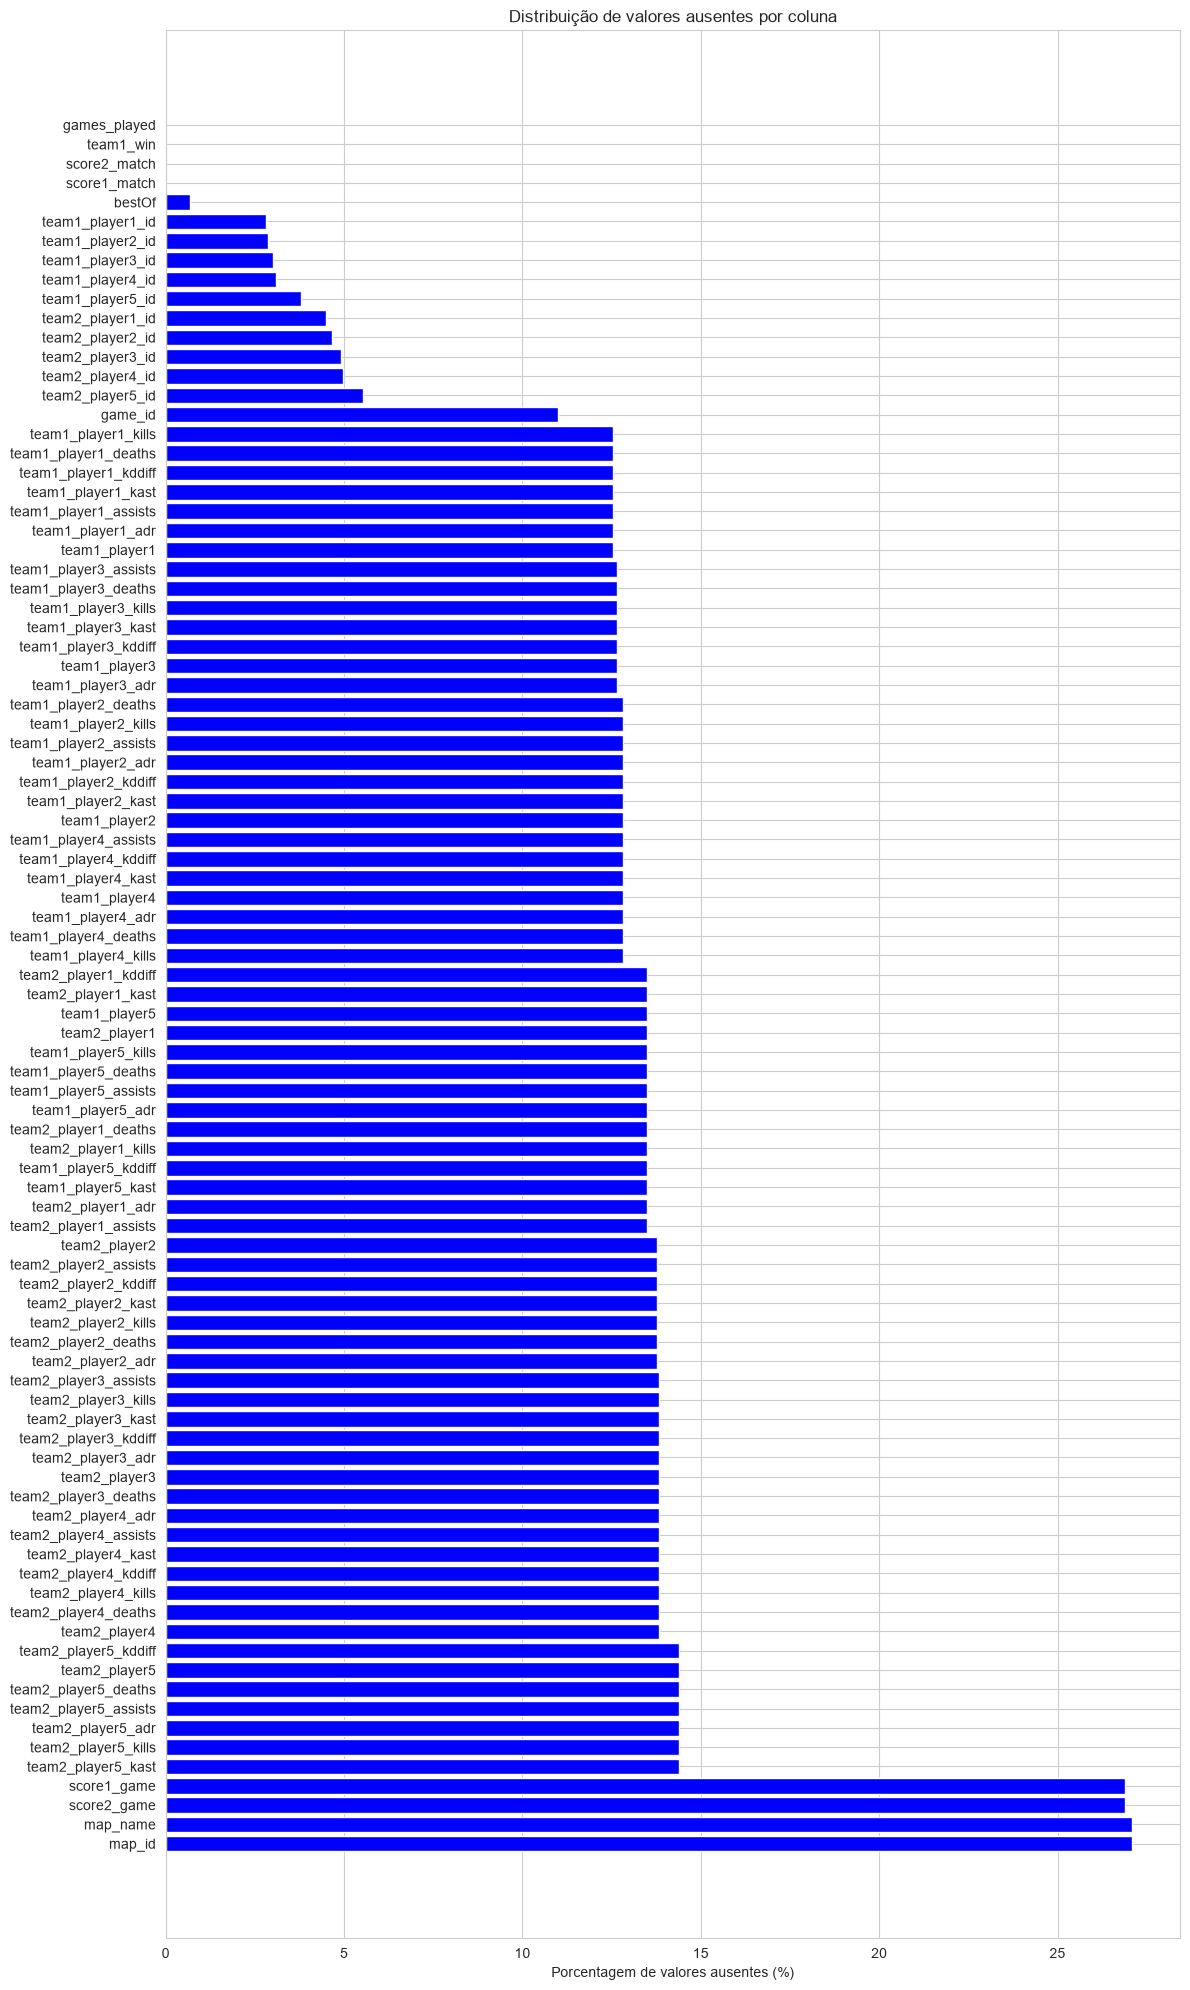

In [92]:
missing_values = pd.DataFrame({
    'Coluna':df_matches.columns,
    'Missing_Count':df_matches.isnull().sum(),
    'Missing_Percentage':(df_matches.isnull().sum()/len(df_matches)*100).round(2)
})
missing_values = missing_values[missing_values['Missing_Count']>0].sort_values(by='Missing_Percentage',ascending=False)

if len(missing_values)>0:
    print(missing_values)
    
    #Gráfico
    plt.figure(figsize=(12, 20))
    plt.barh(missing_values['Coluna'],missing_values['Missing_Percentage'], color='blue')
    plt.xlabel('Porcentagem de valores ausentes (%)')
    plt.title('Distribuição de valores ausentes por coluna')
    plt.tight_layout()
    plt.show()
else:
    print("Não tem Valores ausentes")

## 1.2 Confirmação de granularidade

In [ ]:
print(df_matches['is_total'].value_counts())

print(df_matches[df_matches['map_name'].isna()].groupby('is_total').size())

print(df_matches['match_id'].value_counts())

partida = 7306663

df_matches[df_matches['match_id']==partida]
colunas = [
    'match_id',
    'game_id',
    'is_total',
    'bestOf',
    'map_name',
    'score1_match',
    'score2_match'
]
print(df_matches.loc[df_matches['match_id'] == partida, colunas])

is_total
False    7796
True     5166
Name: count, dtype: int64
is_total
False      44
True     3466
dtype: int64
match_id
7312556     6
7306663     6
7299109     6
5039905     6
4340520     6
           ..
10064065    1
10064064    1
10064066    1
10064067    1
10065881    1
Name: count, Length: 5164, dtype: int64
     match_id   game_id  is_total  bestOf map_name  score1_match  score2_match
519   7306663 -154992.0      True     5.0      NaN           2.0           3.0
520   7306663  154992.0     False     5.0    Cache           2.0           3.0
521   7306663  154993.0     False     5.0     Nuke           2.0           3.0
522   7306663  154994.0     False     5.0    Dust2           2.0           3.0
523   7306663  154995.0     False     5.0   Mirage           2.0           3.0
524   7306663  154996.0     False     5.0  Inferno           2.0           3.0


# **2. Entendendo a tabela de times**

In [93]:
path= "teams.csv"

df_teams= pd.read_csv(path)
print ({df_teams.shape})
pd.set_option('display.max_columns',None)
df_teams.head(5)

{(22856, 2)}


,team_id,team_name
0,232751,Team Vitality
1,232752,BetBoom Team
2,232753,FaZe Clan
3,232754,GamerLegion
4,232755,Natus Vincere


In [94]:
time = 'Team Vitality'
print(df_teams.loc[df_teams['team_name'] == time])

       team_id      team_name
0       232751  Team Vitality
164     233191  Team Vitality
570     234117  Team Vitality
580     234127  Team Vitality
884     235083  Team Vitality
...        ...            ...
22718   306423  Team Vitality
22738   306443  Team Vitality
22752   306839  Team Vitality
22758   306845  Team Vitality
22760   306847  Team Vitality

[226 rows x 2 columns]


## 2.1 Verificando repitibilidade do id

In [95]:
print(df_teams.columns.tolist())
print(df_matches.columns.tolist())

['team_id', 'team_name']
['match_id', 'game_id', 'tournament', 'team1_id', 'team1', 'team2_id', 'team2', 'score1_match', 'score2_match', 'is_total', 'bestOf', 'score1_game', 'score2_game', 'map_id', 'map_name', 'datetime', 'team1_win', 'games_played', 'team1_player1_id', 'team1_player2_id', 'team1_player3_id', 'team1_player4_id', 'team1_player5_id', 'team2_player1_id', 'team2_player2_id', 'team2_player3_id', 'team2_player4_id', 'team2_player5_id', 'team1_player1', 'team1_player2', 'team1_player3', 'team1_player4', 'team1_player5', 'team2_player1', 'team2_player2', 'team2_player3', 'team2_player4', 'team2_player5', 'team1_player1_kills', 'team1_player1_deaths', 'team1_player1_assists', 'team1_player1_adr', 'team1_player1_kast', 'team1_player1_kddiff', 'team1_player2_kills', 'team1_player2_deaths', 'team1_player2_assists', 'team1_player2_adr', 'team1_player2_kast', 'team1_player2_kddiff', 'team1_player3_kills', 'team1_player3_deaths', 'team1_player3_assists', 'team1_player3_adr', 'team1_

In [99]:
equipes_partidas = df_matches.melt(
    id_vars=['match_id', 'tournament'],
    value_vars=['team1_id', 'team2_id'],
    value_name='team_id'
)

analise = equipes_partidas.groupby('team_id').agg(
    partidas = ('match_id','nunique'),
    campeonatos = ('tournament', 'nunique')
)
display(analise)

equipes_partidas['team_id'].isin(df_teams['team_id']).value_counts()

,partidas,campeonatos
team_id,,
232751,1,1
232752,1,1
232753,1,1
232754,1,1
232755,1,1
...,...,...
307122,1,1
307123,1,1
307124,1,1


team_id
True    25924
Name: count, dtype: int64

### **ID único por partida**


In [126]:
print(df_matches['team1_id'].value_counts(),df_matches['team2_id'].value_counts())
codigo1 = 306849
codigo2 = 289673

df_matches.loc[df_matches['team1_id'] == codigo1]

team1_id
306849    6
302814    6
289672    6
279928    6
260088    6
         ..
232753    1
232751    1
232755    1
232757    1
236385    1
Name: count, Length: 5164, dtype: int64 team2_id
306850    6
302815    6
289673    6
279929    6
260089    6
         ..
232754    1
232752    1
232756    1
232758    1
236386    1
Name: count, Length: 5164, dtype: int64


,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,datetime,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,team1_player4_id,team1_player5_id,team2_player1_id,team2_player2_id,team2_player3_id,team2_player4_id,team2_player5_id,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5,team1_player1_kills,team1_player1_deaths,team1_player1_assists,team1_player1_adr,team1_player1_kast,team1_player1_kddiff,team1_player2_kills,team1_player2_deaths,team1_player2_assists,team1_player2_adr,team1_player2_kast,team1_player2_kddiff,team1_player3_kills,team1_player3_deaths,team1_player3_assists,team1_player3_adr,team1_player3_kast,team1_player3_kddiff,team1_player4_kills,team1_player4_deaths,team1_player4_assists,team1_player4_adr,team1_player4_kast,team1_player4_kddiff,team1_player5_kills,team1_player5_deaths,team1_player5_assists,team1_player5_adr,team1_player5_kast,team1_player5_kddiff,team2_player1_kills,team2_player1_deaths,team2_player1_assists,team2_player1_adr,team2_player1_kast,team2_player1_kddiff,team2_player2_kills,team2_player2_deaths,team2_player2_assists,team2_player2_adr,team2_player2_kast,team2_player2_kddiff,team2_player3_kills,team2_player3_deaths,team2_player3_assists,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
96,7312556,-155921.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,True,5.0,NaN,NaN,NaN,NaN,2026-10-31 14:00:00,1.0,5.0,564.0,26759.0,625.0,1.0,628.0,3344.0,7440.0,26179.0,2163.0,6142.0,"YEKINDAR (Mareks Gaļinskis), LV",molodoy,"yuurih (Yuri Santos), BR","FalleN (Gabriel Toledo), BR","KSCERATO (Kaike Cerato), BR","Xant3r (Kirill Kononov), RU","robo (Nikita Dushin), RU",syph0,"KaiR0N (Aleksandr Anashkin), RU","khaN, KZ",82.0,57.0,30.0,100.9,76.7,25.0,59.0,58.0,19.0,64.9,70.0,1.0,56.0,56.0,27.0,74.8,74.6,0.0,65.0,57.0,18.0,70.7,73.0,8.0,64.0,49.0,24.0,81.5,74.6,15.0,49.0,67.0,21.0,68.7,59.9,-18.0,54.0,66.0,15.0,66.4,61.9,-12.0,46.0,66.0,18.0,60.3,67.8,-20.0,58.0,74.0,15.0,71.2,59.7,-16.0,67.0,54.0,18.0,69.7,71.9,13.0
97,7312556,155921.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,2.0,13.0,24.0,Ancient,2026-10-31 14:00:00,1.0,5.0,564.0,26759.0,625.0,1.0,628.0,3344.0,7440.0,26179.0,2163.0,6142.0,"YEKINDAR (Mareks Gaļinskis), LV",molodoy,"yuurih (Yuri Santos), BR","FalleN (Gabriel Toledo), BR","KSCERATO (Kaike Cerato), BR","Xant3r (Kirill Kononov), RU","robo (Nikita Dushin), RU",syph0,"KaiR0N (Aleksandr Anashkin), RU","khaN, KZ",15.0,10.0,6.0,108.1,86.7,5.0,2.0,13.0,1.0,33.2,40.0,-11.0,8.0,11.0,3.0,69.5,60.0,-3.0,6.0,13.0,2.0,53.1,53.3,-7.0,9.0,14.0,3.0,74.9,60.0,-5.0,13.0,8.0,4.0,99.7,80.0,5.0,15.0,9.0,3.0,106.5,80.0,6.0,7.0,9.0,8.0,59.9,80.0,-2.0,17.0,10.0,2.0,98.8,80.0,7.0,9.0,4.0,6.0,59.9,80.0,5.0
98,7312556,155922.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,Nemiga Gaming,3.0,2.0,False,5.0,13.0,5.0,6.0,Dust2,2026-10-31 14:00:00,1.0,5.0,564.0,26759.0,625.0,1.0,628.0,3344.0,7440.0,26179.0,2163.0,6142.0,"YEKINDAR (Mareks Gaļinskis), LV",molodoy,"yuurih (Yuri Santos), BR","FalleN (Gabriel Toledo), BR","KSCERATO (Kaike Cerato), BR","Xant3r (Kirill Kononov), RU","robo (Nikita Dushin), RU",syph0,"KaiR0N (Aleksandr Anashkin), RU","khaN, KZ",17.0,12.0,6.0,92.2,72.2,5.0,13.0,12.0,6.0,86.9,72.2,1.0,12.0,9.0,4.0,66.8,83.3,3.0,14.0,10.0,3.0,69.4,77.8,4.0,13.0,8.0,8.0,85.2,88.9,5.0,6.0,14.0,3.0,44.7,44.4,-8.0,6.0,15.0,3.0,48.4,66.7,-9.0,10.0,14.0,1.0,63.2,61.1,-4.0,9.0,17.0,1.0,61.9,50.0,-8.0,19.0,9.0,2.0,102.3,77.8,10.0
99,7312556,155923.0,PGL Masters Bucharest 2026,306849,FURIA Esports,306850,N

In [142]:
times=pd.concat([df_matches['team1'],df_matches['team2']]).unique()
times.sort()

print(type(times))
display(times)

<class 'pandas.arrays.StringArray'>


<StringArray>
[                       '-72C',                    '00Nation',
                 '100 Thieves',           '15 Average Gaming',
                        '1ADL',                     '1w Team',
                   '1win Team',                  '2ez Gaming',
                         '500',               '5star eSports',
 ...
                    'Хорватия',                       'Чехия',
                        'Чили',                   'Швейцария',
                      'Швеция',                     'Эстония',
                 'Южная Корея', 'Южно-Африканская Республика',
                      'Япония',                        '秽土转生']
Length: 580, dtype: str

In [147]:
print(df_matches[df_matches['team1'].isna()],df_matches[df_matches['team2'].isna()])

nomes = ['1win Team', '1w Team']

for nome in nomes:
    partidas = df_matches[
        (df_matches['team1'] == nome) |
        (df_matches['team2'] == nome)
    ]

    datas = pd.to_datetime(partidas['datetime'])

    print(f'{nome}:')
    print('Primeira partida:', datas.min())
    print('Última partida:', datas.max())

Empty DataFrame
Columns: [match_id, game_id, tournament, team1_id, team1, team2_id, team2, score1_match, score2_match, is_total, bestOf, score1_game, score2_game, map_id, map_name, datetime, team1_win, games_played, team1_player1_id, team1_player2_id, team1_player3_id, team1_player4_id, team1_player5_id, team2_player1_id, team2_player2_id, team2_player3_id, team2_player4_id, team2_player5_id, team1_player1, team1_player2, team1_player3, team1_player4, team1_player5, team2_player1, team2_player2, team2_player3, team2_player4, team2_player5, team1_player1_kills, team1_player1_deaths, team1_player1_assists, team1_player1_adr, team1_player1_kast, team1_player1_kddiff, team1_player2_kills, team1_player2_deaths, team1_player2_assists, team1_player2_adr, team1_player2_kast, team1_player2_kddiff, team1_player3_kills, team1_player3_deaths, team1_player3_assists, team1_player3_adr, team1_player3_kast, team1_player3_kddiff, team1_player4_kills, team1_player4_deaths, team1_player4_assists, team1_p

In [152]:
nomes = ['1win Team', '1w Team']

def partidas(nome):
    return df_matches[
        (df_matches['team1'] == nome) |
        (df_matches['team2'] == nome)
    ]
antigo,recente = sorted(
    nomes,
    key=lambda nome:pd.to_datetime(partidas(nome)['datetime']).min()
)
ultima = partidas(antigo).sort_values('datetime').iloc[-1]
primeira = partidas(recente).sort_values('datetime').iloc[0]
colunas=[
    'team1_player1',
    'team1_player2',
    'team1_player3',
    'team1_player4',
    'team1_player5',
    'team2_player1',
    'team2_player2',
    'team2_player3',
    'team2_player4',
    'team2_player5',
]
    
display(df_matches.loc[df_matches['match_id'] == ultima['match_id'],colunas])
display(df_matches.loc[df_matches['match_id'] == primeira['match_id'],colunas])

,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5
3618,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5
2114,"qikert (Alexey Golubev), KZ","reyozdead, RU","latt1kk (Vladislav Vydrin), RU","Oz1k, RU",cronuss,"k1to (Nils Gruhne), DE","Altekz (Alexander Givskov), DK","L00m1 (Lucas Haukland), SE","myltsi (Ville Vilkman), FI","mAriX (Max Kugener), LU"
2115,"qikert (Alexey Golubev), KZ","reyozdead, RU","latt1kk (Vladislav Vydrin), RU","Oz1k, RU",cronuss,"k1to (Nils Gruhne), DE","Altekz (Alexander Givskov), DK","L00m1 (Lucas Haukland), SE","myltsi (Ville Vilkman), FI","mAriX (Max Kugener), LU"


In [154]:
display(df_matches.loc[(df_matches['team1']=='1win Team')|(df_matches['team2']=='1win Team'),colunas])

,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5
3618,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5386,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9201,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9252,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9286,"xfl0ud (Yasin Koç), TR","LNZ (Linus Holtäng), SE","Yxngstxr (Simon Boije), SE","jottA (Samet Köklü), TR","SaMey (Dawid Stańczak), PL","neaLaN (Sanzhar Ishkakov), KZ","buster (Timur Tulepov), KZ","latt1kk (Vladislav Vydrin), RU","Ryujin (Boris Kim), UZ","HObbit (Abay Khasenov), KZ"
9287,"xfl0ud (Yasin Koç), TR","LNZ (Linus Holtäng), SE","Yxngstxr (Simon Boije), SE","jottA (Samet Köklü), TR","SaMey (Dawid Stańczak), PL","neaLaN (Sanzhar Ishkakov), KZ","buster (Timur Tulepov), KZ","latt1kk (Vladislav Vydrin), RU","Ryujin (Boris Kim), UZ","HObbit (Abay Khasenov), KZ"
9318,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9599,"neaLaN (Sanzhar Ishkakov), KZ","buster (Timur Tulepov), KZ","latt1kk (Vladislav Vydrin), RU","Ryujin (Boris Kim), UZ","HObbit (Abay Khasenov), KZ","Polt (Vadim Tsyrov), RU",NaN,"FpSSS (Dmitriy Sofronov), RU","faydett (Yuri Martirosov), RU","sugaR (Amin Azimov), AZ"


### **Escalações diferentes; relação entre as organizações não confirmada. Nomes mantidos separados.**

In [187]:
contagem = df_matches[df_matches['is_total'] == True].groupby('match_id').size()

display(contagem.value_counts())
display(contagem[contagem>1])


1    5164
Name: count, dtype: int64

Series([], dtype: int64)

In [191]:
df_matches[df_matches['match_id']==7298940]

,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,datetime,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,team1_player4_id,team1_player5_id,team2_player1_id,team2_player2_id,team2_player3_id,team2_player4_id,team2_player5_id,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5,team1_player1_kills,team1_player1_deaths,team1_player1_assists,team1_player1_adr,team1_player1_kast,team1_player1_kddiff,team1_player2_kills,team1_player2_deaths,team1_player2_assists,team1_player2_adr,team1_player2_kast,team1_player2_kddiff,team1_player3_kills,team1_player3_deaths,team1_player3_assists,team1_player3_adr,team1_player3_kast,team1_player3_kddiff,team1_player4_kills,team1_player4_deaths,team1_player4_assists,team1_player4_adr,team1_player4_kast,team1_player4_kddiff,team1_player5_kills,team1_player5_deaths,team1_player5_assists,team1_player5_adr,team1_player5_kast,team1_player5_kddiff,team2_player1_kills,team2_player1_deaths,team2_player1_assists,team2_player1_adr,team2_player1_kast,team2_player1_kddiff,team2_player2_kills,team2_player2_deaths,team2_player2_assists,team2_player2_adr,team2_player2_kast,team2_player2_kddiff,team2_player3_kills,team2_player3_deaths,team2_player3_assists,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff
2706,7298940,-153267.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,True,3.0,NaN,NaN,NaN,NaN,2026-04-02 11:00:00,0.0,3.0,8188.0,4549.0,4792.0,26335.0,3323.0,27.0,8274.0,3513.0,6665.0,11.0,Djon8,"1NVISIBLE (Danila Simagin), RU","k4nfuz (Vladislav Shilov), RU",xm1nd,"SoLb (Kirill Simagin), RU","rain (Håvard Nygaard), NO",poiii,"Ag1L (André Gil), PT","sirah (William Kjærsgaard), DK","device (Nicolai Reedtz), DK",41.0,38.0,8.0,80.2,70.4,3.0,27.0,43.0,10.0,62.2,66.6,-16.0,31.0,37.0,12.0,59.8,75.5,-6.0,32.0,35.0,8.0,57.7,71.8,-3.0,38.0,40.0,9.0,81.3,73.7,-2.0,42.0,36.0,21.0,94.9,72.8,6.0,34.0,39.0,18.0,75.2,76.2,-5.0,39.0,30.0,15.0,84.2,80.7,9.0,38.0,30.0,11.0,70.9,73.8,8.0,40.0,34.0,9.0,76.2,74.7,6.0
2707,7298940,153266.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,False,3.0,1.0,13.0,2.0,Nuke,2026-04-02 11:00:00,0.0,3.0,8188.0,4549.0,4792.0,26335.0,3323.0,27.0,8274.0,3513.0,6665.0,11.0,Djon8,"1NVISIBLE (Danila Simagin), RU","k4nfuz (Vladislav Shilov), RU",xm1nd,"SoLb (Kirill Simagin), RU","rain (Håvard Nygaard), NO",poiii,"Ag1L (André Gil), PT","sirah (William Kjærsgaard), DK","device (Nicolai Reedtz), DK",4.0,13.0,1.0,39.9,42.9,-9.0,10.0,14.0,1.0,79.3,57.1,-4.0,6.0,14.0,3.0,54.1,78.6,-8.0,6.0,13.0,2.0,35.2,57.1,-7.0,7.0,14.0,2.0,65.9,57.1,-7.0,16.0,6.0,8.0,109.6,92.9,10.0,13.0,9.0,3.0,94.1,92.9,4.0,11.0,5.0,6.0,96.4,100.0,6.0,11.0,6.0,3.0,78.8,85.7,5.0,17.0,7.0,1.0,103.1,71.4,10.0
2708,7298940,153267.0,PGL Astana 2026. Закрытая европейская квалифик...,289666,Lavked,289667,100 Thieves,1.0,2.0,False,3.0,13.0,5.0,24.0,Ancient,2026-04-02 11:00:00,0.0,3.0,8188.0,4549.0,4792.0,26335.0,3323.0,27.0,8274.0,3513.0,6665.0,11.0,Djon8,"1NVISIBLE (Danila Simagin), RU","k4nfuz (Vladislav Shilov), RU",xm1nd,"SoLb (Kirill Simagin), RU","rain (Håvard Nygaard), NO",poiii,"Ag1L (André Gil), PT","sirah (William Kjærsgaard), DK","device (Nicolai Reedtz), DK",20.0,11.0,3.0,117.2,83.3,9.0,9.0,12.0,2.0,53.8,77.8,-3.0,10.0,10.0,7.0,56.8,77.8,0.0,15.0,9.0,4.0,84.0,83.3,6.0,14.0,11.0,3.0,77.8,88.9,3.0,7.0,16.0,5.0,70.0,55.6,-9.0,10.0,14.0,6.0,69.2,55.6,-4.0,14.0,12.0,4.0,71.3,72.2,2.0,9.0,13.0,5.0,60.8,55.6,-4.0,13.0,13.0,3.0,62.8,77.8,0.0
2709,7298940,153268.0,PGL Astana 2026. Закрытая европейская квалифик

In [198]:
excluir = (
    (df_matches['match_id'] == 7298940)
    & (df_matches['is_total'] == True)
    & (df_matches['tournament'] == 'PGL Astana 2026. Closed European Qualifier')
)
excluir2 = (
    (df_matches['match_id'] == 7287899)
    & (df_matches['is_total'] == True)
    & (df_matches['tournament'] == 'PGL Astana 2026. Closed European Qualifier') 
)

display(df_matches.loc[excluir],df_matches.loc[excluir2])

,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,datetime,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,team1_player4_id,team1_player5_id,team2_player1_id,team2_player2_id,team2_player3_id,team2_player4_id,team2_player5_id,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5,team1_player1_kills,team1_player1_deaths,team1_player1_assists,team1_player1_adr,team1_player1_kast,team1_player1_kddiff,team1_player2_kills,team1_player2_deaths,team1_player2_assists,team1_player2_adr,team1_player2_kast,team1_player2_kddiff,team1_player3_kills,team1_player3_deaths,team1_player3_assists,team1_player3_adr,team1_player3_kast,team1_player3_kddiff,team1_player4_kills,team1_player4_deaths,team1_player4_assists,team1_player4_adr,team1_player4_kast,team1_player4_kddiff,team1_player5_kills,team1_player5_deaths,team1_player5_assists,team1_player5_adr,team1_player5_kast,team1_player5_kddiff,team2_player1_kills,team2_player1_deaths,team2_player1_assists,team2_player1_adr,team2_player1_kast,team2_player1_kddiff,team2_player2_kills,team2_player2_deaths,team2_player2_assists,team2_player2_adr,team2_player2_kast,team2_player2_kddiff,team2_player3_kills,team2_player3_deaths,team2_player3_assists,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff


,match_id,game_id,tournament,team1_id,team1,team2_id,team2,score1_match,score2_match,is_total,bestOf,score1_game,score2_game,map_id,map_name,datetime,team1_win,games_played,team1_player1_id,team1_player2_id,team1_player3_id,team1_player4_id,team1_player5_id,team2_player1_id,team2_player2_id,team2_player3_id,team2_player4_id,team2_player5_id,team1_player1,team1_player2,team1_player3,team1_player4,team1_player5,team2_player1,team2_player2,team2_player3,team2_player4,team2_player5,team1_player1_kills,team1_player1_deaths,team1_player1_assists,team1_player1_adr,team1_player1_kast,team1_player1_kddiff,team1_player2_kills,team1_player2_deaths,team1_player2_assists,team1_player2_adr,team1_player2_kast,team1_player2_kddiff,team1_player3_kills,team1_player3_deaths,team1_player3_assists,team1_player3_adr,team1_player3_kast,team1_player3_kddiff,team1_player4_kills,team1_player4_deaths,team1_player4_assists,team1_player4_adr,team1_player4_kast,team1_player4_kddiff,team1_player5_kills,team1_player5_deaths,team1_player5_assists,team1_player5_adr,team1_player5_kast,team1_player5_kddiff,team2_player1_kills,team2_player1_deaths,team2_player1_assists,team2_player1_adr,team2_player1_kast,team2_player1_kddiff,team2_player2_kills,team2_player2_deaths,team2_player2_assists,team2_player2_adr,team2_player2_kast,team2_player2_kddiff,team2_player3_kills,team2_player3_deaths,team2_player3_assists,team2_player3_adr,team2_player3_kast,team2_player3_kddiff,team2_player4_kills,team2_player4_deaths,team2_player4_assists,team2_player4_adr,team2_player4_kast,team2_player4_kddiff,team2_player5_kills,team2_player5_deaths,team2_player5_assists,team2_player5_adr,team2_player5_kast,team2_player5_kddiff


In [ ]:
df_matches = df_matches.loc[~excluir].copy()
df_matches = df_matches.loc[~excluir2].copy()